# **Lab project 2: Advanced deep generative models**

**Pablo Martínez Olmos, Vanessa Gómez Verdejo,  Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='https://upload.wikimedia.org/wikipedia/commons/8/88/Acronimo_nombre3l.jpg' width=300 />


# Part 1: Conditional Generation in Deep Generative Models

In this first part, you will progressively explore the design and training of Variational Autoencoders (VAEs) using the **Fashion MNIST** dataset ([torchvision.datasets.FashionMNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html)). The first part will guide you through building a standard VAE, experimenting with different likelihoods, and analyzing the latent space. As you advance, you will extend your models to more expressive approaches, culminating in the implementation and analysis of conditional VAEs. Each section will build upon the previous, helping you understand how architectural choices and conditioning impact generative modeling and representation learning.

The notebook is structured so that each section introduces a new concept or modeling challenge, leading you step by step from basic VAEs to conditional generative models.

## Exercise 1: Standard VAE Training and Likelihood Comparison

In this exercise, you will:
- Implement and train a standard VAE on FashionMNIST.
- Compare two likelihoods for the decoder: Gaussian and soft Bernoulli.
- Analyze and discuss the reconstruction quality and latent space for each likelihood.

<span style="color: blue;">Luis Manuel García Muñoz: comments in blue.</span>

<span style="color: blue;">We import the necessary libraries for implementing Variational Autoencoders (VAEs).</span>

In [1]:
from torchvision.datasets import FashionMNIST
from torchvision import transforms
from torchinfo import summary

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np

from torchvision import datasets, transforms

import pytorch_lightning as pl

from PIL import Image

from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor

from torch.utils.data import Dataset, DataLoader

import pandas as pd

from matplotlib import pyplot as plt

<span style="color: blue;">We download the dataset.</span>

In [2]:
fashion_labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}


class Fashion_MNIST(Dataset):
    def __init__(self, mode='train'):
        if mode == 'train':
            self.data = FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
        elif mode in ('val', 'test'):
            eval_dataset = FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())
            val_size = len(eval_dataset) // 2
            # Use the same seed so validation and test are disjoint halves.
            val_data, test_data = torch.utils.data.random_split(
                eval_dataset,
                [val_size, len(eval_dataset) - val_size],
                generator=torch.Generator().manual_seed(42)
            )
            self.data = val_data if mode == 'val' else test_data
        else:
            raise ValueError("Mode should be 'train', 'val', or 'test'")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, imgtype = self.data[idx]
        # Flatten the 28x28 image to a 784-dimensional vector
        return img.view(-1), imgtype



train_dataset = Fashion_MNIST(mode='train')
val_dataset = Fashion_MNIST(mode='val')
test_dataset = Fashion_MNIST(mode='test')


Type is Trouser


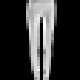

In [3]:
index = np.random.randint(len(test_dataset))

image, imgtype = test_dataset[index]

print("Type is", fashion_labels[imgtype])

img = image.reshape(28, 28).numpy()
img = (img * 255).clip(0, 255).astype(np.uint8)

display(Image.fromarray(img).resize((80, 80), Image.Resampling.NEAREST))

<span style="color: blue;">VAE code</span>

In [4]:
EPS = 1e-8




class Encoder(nn.Module):
    def __init__(self, encoder_net):
        super(Encoder, self).__init__()

        # The encoder network (e.g., MLP) that outputs concatenated [mu, log_var]
        self.encoder_net = encoder_net

    def reparameterization(self, mu, log_var):
        # Reparameterization trick:
        # Sample z ~ N(mu, sigma^2) using z = mu + sigma * epsilon,
        # where epsilon ~ N(0, I)
        std = torch.exp(0.5 * log_var)        # Convert log variance to standard deviation
        eps = torch.randn_like(std)           # Sample epsilon with the same shape as std (L=1)
        return mu + std * eps                 # Sample z

    def encode(self, x):
        # Forward input x through the encoder network to get mu and log_var
        h_e = self.encoder_net(x)                 # Output is of size 2M
        mu_e, log_var_e = torch.chunk(h_e, 2, dim=1)  # Split into two parts: mean and log variance
        return mu_e, log_var_e

    def sample(self, x=None, mu_e=None, log_var_e=None):
        # Return a sample from the approximate posterior
        # Can either compute mu/log_var from x or take them as input
        if (mu_e is None) and (log_var_e is None):
            mu_e, log_var_e = self.encode(x)
        else:
            if (mu_e is None) or (log_var_e is None):
                raise ValueError('mu and log_var can\'t be None!')
        z = self.reparameterization(mu_e, log_var_e)
        return z



class GaussianLikelyhoodDecoder(nn.Module):
    def __init__(self, decoder_net, fixed_var=1.0):
        super(GaussianLikelyhoodDecoder, self).__init__()
        self.decoder_net = decoder_net
        self.register_buffer("var", torch.tensor(float(fixed_var)))  # Saved in checkpoints

    def decode(self, z):
        # We only learn the mean of p(x|z), variance is fixed
        mu = self.decoder_net(z)
        return mu

    def sample(self, z):
        mu = self.decode(z)
        std = self.var.sqrt()
        eps = torch.randn_like(mu)
        return mu + eps * std


    def log_prob(self, x, z):
        mu = self.decode(z)
        # log N(x | mu, sigma^2 I) with fixed variance
        log_prob = -0.5 * ((x - mu) ** 2) / self.var - 0.5 * torch.log(2 * torch.pi * self.var)
        # Note that first term is the MSE and second term is a constant depending on variance
        return log_prob.sum(dim=-1)


class Prior(nn.Module):
    def __init__(self, M):
        super(Prior, self).__init__()
        # M is the dimensionality of the latent space
        self.M = M

    def sample(self, batch_size):
        # Sample from a standard normal distribution (mean=0, std=1)
        z = torch.randn((batch_size, self.M))  # Shape: (batch_size, latent_dim)
        return z

class VAE(nn.Module):
    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.prior = Prior(M=encoder.encoder_net[-1].out_features // 2)

    def __compute_RE(self, x, z):
        return self.decoder.log_prob(x, z)

    def __compute_KL(self, mu_e, log_var_e):
        return 0.5 * torch.sum(torch.exp(log_var_e) + mu_e**2 - 1 - log_var_e, dim=1)

    def forward(self, x):
        # generate a latent variable, for each training sample, with the encoder
        mu_e, log_var_e = self.encoder.encode(x)
        z = self.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)

        # ELBO
        
        RE = self.__compute_RE(x, z)
        KL = self.__compute_KL(mu_e, log_var_e)
        return (-RE + KL).mean(), dict(RE=RE.mean(), KL=KL.mean())

        
    def sample(self, batch_size=64):
        # Generate a latent variable with the prior
        param = next(self.decoder.parameters())
        z = torch.randn(batch_size, self.prior.M, device=param.device, dtype=param.dtype)
        return self.decoder.sample(z)





<span style="color: blue;">Lighting generic model.</span>

In [5]:
class LitGenericVAEModel(pl.LightningModule):
    def __init__(self, vae_model,lr=1e-3):
        super().__init__()
        self.save_hyperparameters(ignore=['vae_model'])  # logs hyperparameters automatically

        self.vae_model = vae_model

    def forward(self, x):
        return self.vae_model(x)

    def _shared_step(self, batch):
        xs, ys = batch

        loss, score_dict = self(xs)
  
        return loss, score_dict

    def training_step(self, batch, batch_idx):
        loss, score_dict = self._shared_step(batch)
        self.log('loss.train', loss, on_epoch=True, on_step=False, prog_bar=False)
        for name, score in score_dict.items():
            self.log(f'score.{name}.train', score, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, score_dict = self._shared_step(batch)
        self.log('loss.valid', loss, on_epoch=True, on_step=False, prog_bar=False)
        for name, score in score_dict.items():
            self.log(f'score.{name}.valid', score, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def test_step(self, batch, batch_idx):
        loss, score_dict = self._shared_step(batch)
        self.log('loss.test', loss, on_epoch=True, on_step=False, prog_bar=False)
        for name, score in score_dict.items():
            self.log(f'score.{name}.test', score, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

<span style="color: blue;">Helper function to generate MLP.</span>

In [6]:


def make_mlp(input_dim, output_dim, num_hidden_layers, neurons_per_layer):
    layers = []
    current_dim = input_dim

    for _ in range(num_hidden_layers):
        layers.append(nn.Linear(current_dim, neurons_per_layer))
        layers.append(nn.LeakyReLU())
        current_dim = neurons_per_layer

    layers.append(nn.Linear(current_dim, output_dim))
    return nn.Sequential(*layers)

<span style="color: blue;">VAE with Gaussian Likelyhood.</span>

In [7]:
input_dim = train_dataset[0][0].numel()


num_hidden_layers = 2
num_hidden_layer_neurons = 64

latent_dim = 64



encoder =  Encoder(encoder_net=make_mlp(input_dim, 2 * latent_dim, num_hidden_layers, num_hidden_layer_neurons))
decoder = GaussianLikelyhoodDecoder(decoder_net=make_mlp(latent_dim, input_dim, num_hidden_layers, num_hidden_layer_neurons), fixed_var=0.1)



vae = VAE(encoder, decoder)


In [8]:
summary(vae, input_size=(1,input_dim))

Layer (type:depth-idx)                   Output Shape              Param #
VAE                                      --                        --
├─Encoder: 1-1                           --                        --
│    └─Sequential: 2-1                   [1, 128]                  --
│    │    └─Linear: 3-1                  [1, 64]                   50,240
│    │    └─LeakyReLU: 3-2               [1, 64]                   --
│    │    └─Linear: 3-3                  [1, 64]                   4,160
│    │    └─LeakyReLU: 3-4               [1, 64]                   --
│    │    └─Linear: 3-5                  [1, 128]                  8,320
├─GaussianLikelyhoodDecoder: 1-2         --                        --
│    └─Sequential: 2-2                   [1, 784]                  --
│    │    └─Linear: 3-6                  [1, 64]                   4,160
│    │    └─LeakyReLU: 3-7               [1, 64]                   --
│    │    └─Linear: 3-8                  [1, 64]                   4,160

In [9]:
%%time

num_epochs = 20



lit_model = LitGenericVAEModel(vae_model=vae)

logger = CSVLogger(
    save_dir="lightning_logs",
    name="VAE_NormalLikelihood",
    version="fixed"
)


checkpoint = ModelCheckpoint(
    dirpath="./lightning_logs/VAE_NormalLikelihood/fixed/checkpoints",
    filename="vae-best-{epoch:02d}",
    monitor="loss.valid",
    mode="min",
    save_top_k=1,
)


early_stopping = EarlyStopping(
    monitor="loss.valid",
    mode="min",
    patience=5,
    min_delta=0.0,
)



trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=50,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger,
    callbacks=[checkpoint, early_stopping])

train_data_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightning_logs/VAE_NormalLikelihood/fixed exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/Topic4/lightning_logs/VAE_NormalLikelihood/fixed/checkpoints exists and is not empty.

  | Name      | Type | Params | Mode  | FLOPs
-----------------

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 19: 100%|██████████| 938/938 [00:04<00:00, 221.75it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 19: 100%|██████████| 938/938 [00:04<00:00, 221.21it/s, v_num=ixed]
CPU times: user 1min 7s, sys: 10 s, total: 1min 17s
Wall time: 1min 24s


In [10]:
def plot_training_results(results_path, metric = 'loss'):
    from matplotlib.ticker import MaxNLocator
    
    results = pd.read_csv(results_path)

    results = results.groupby(["epoch", "step"], as_index=False).first()

    plt.plot(results['epoch'], results[metric + ".train"])
    plt.xlabel('Epoch')
    plt.ylabel(metric)
    plt.title(f'Training {metric} over Epochs')
    plt.plot(results['epoch'], results[metric + ".valid"])
    plt.xlabel('Epoch')
    plt.title(f'Validation {metric} over Epochs')
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

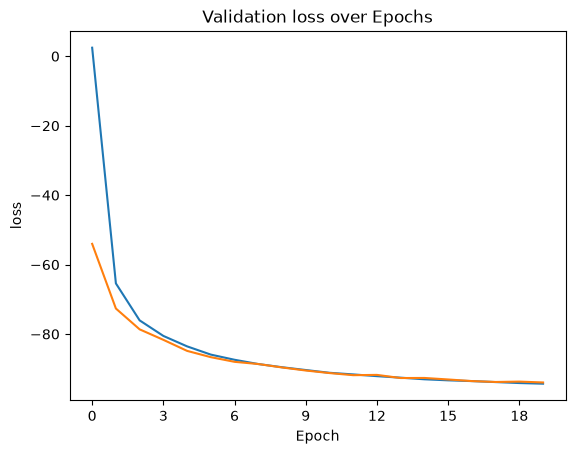

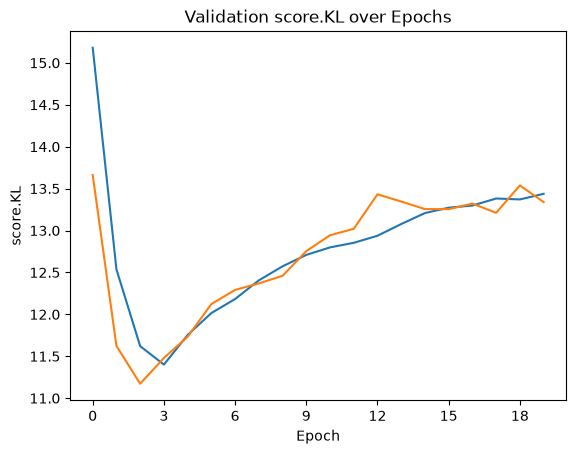

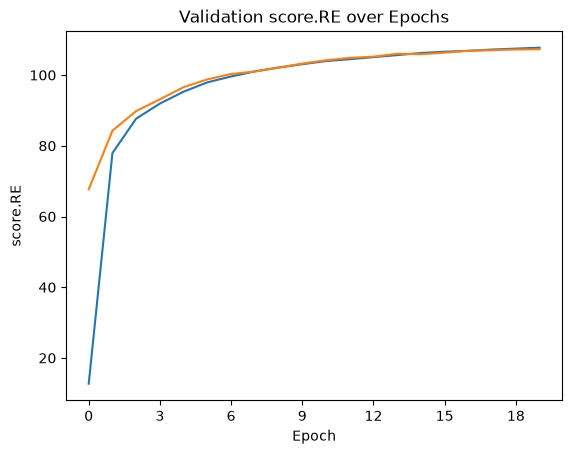

In [11]:
plot_training_results('./lightning_logs/VAE_NormalLikelihood/fixed/metrics.csv', metric='loss')

plot_training_results('./lightning_logs/VAE_NormalLikelihood/fixed/metrics.csv', metric='score.KL')

plot_training_results('./lightning_logs/VAE_NormalLikelihood/fixed/metrics.csv', metric='score.RE')


In [12]:
def samples_generated_noise(model_best):

    model_best.eval()
    num_x = 4
    num_y = 4
    x = model_best.sample(num_x * num_y)
    x = x.detach().cpu().numpy()

    fig, ax = plt.subplots(num_x, num_y)
    for i, ax in enumerate(ax.flatten()):
        plottable_image = np.reshape(x[i], (28, 28))
        ax.imshow(plottable_image, cmap='gray')
        ax.axis('off')

def samples_generated_no_noise(model_best):
    model_best.eval()
    param = next(model_best.parameters())

    with torch.no_grad():
        z = torch.randn(
            16, model_best.prior.M,
            device=param.device, dtype=param.dtype,
        )
        images = model_best.decoder.decode(z).cpu().numpy()

    fig, axes = plt.subplots(4, 4)
    for image, ax in zip(images, axes.flat):
        ax.imshow(
            image.reshape(28, 28),
            cmap="gray", vmin=0, vmax=1,
            interpolation="nearest",
        )
        ax.axis("off")
    plt.show()


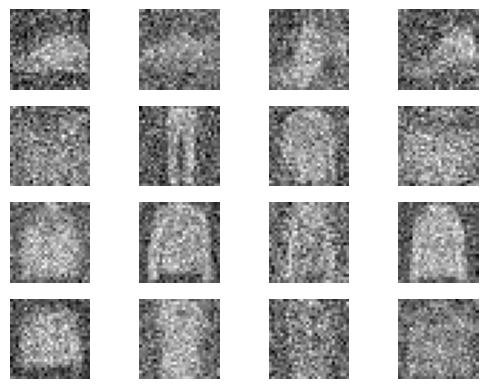

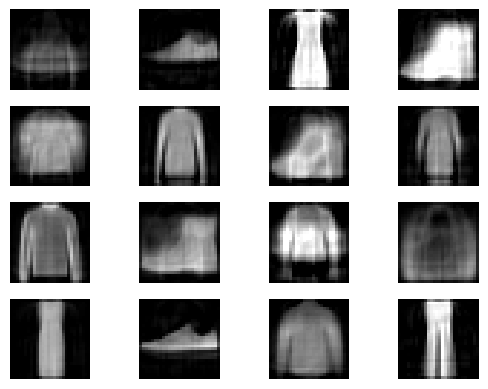

In [13]:
best_model = LitGenericVAEModel.load_from_checkpoint(
    checkpoint.best_model_path,
    vae_model=vae,
)

samples_generated_noise(best_model.vae_model)
samples_generated_no_noise(best_model.vae_model)



In [14]:
def plot_reconstructions_by_label(model_best, test_dataset):
    # Pick one random test image per class, without replacement.
    selected = {}
    for index in torch.randperm(len(test_dataset)).tolist():
        image, label = test_dataset[index]
        label = int(label)
        if label in fashion_labels and label not in selected:
            selected[label] = image
        if len(selected) == len(fashion_labels):
            break

    labels = sorted(fashion_labels)
    if len(selected) != len(labels):
        raise ValueError("The test dataset must contain an image for every label.")

    param = next(model_best.parameters())
    originals = torch.stack([selected[label] for label in labels])
    inputs = originals.to(device=param.device, dtype=param.dtype)
    was_training = model_best.training
    model_best.eval()
    try:
        with torch.no_grad():
            # Use the posterior mean so the no-noise reconstruction is deterministic.
            mu, _ = model_best.encoder.encode(inputs)
            means = model_best.decoder.decode(mu)
            # Delegate sampling to the decoder's likelihood using the same latent vector.
            noisy = model_best.decoder.sample(mu)
            columns = [originals.cpu(), means.cpu(), noisy.cpu()]
    finally:
        model_best.train(was_training)

    fig, axes = plt.subplots(len(labels), 3, figsize=(9, 24), squeeze=False)
    for row, label in enumerate(labels):
        for col, images in enumerate(columns):
            ax = axes[row, col]
            ax.imshow(images[row].reshape(28, 28).numpy(), cmap="gray",
                      vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[row, 0].set_ylabel(fashion_labels[label], rotation=0,
                                ha="right", va="center", labelpad=12)

    for ax, title in zip(axes[0], ["Original", "No noise", "With noise"]):
        ax.set_title(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


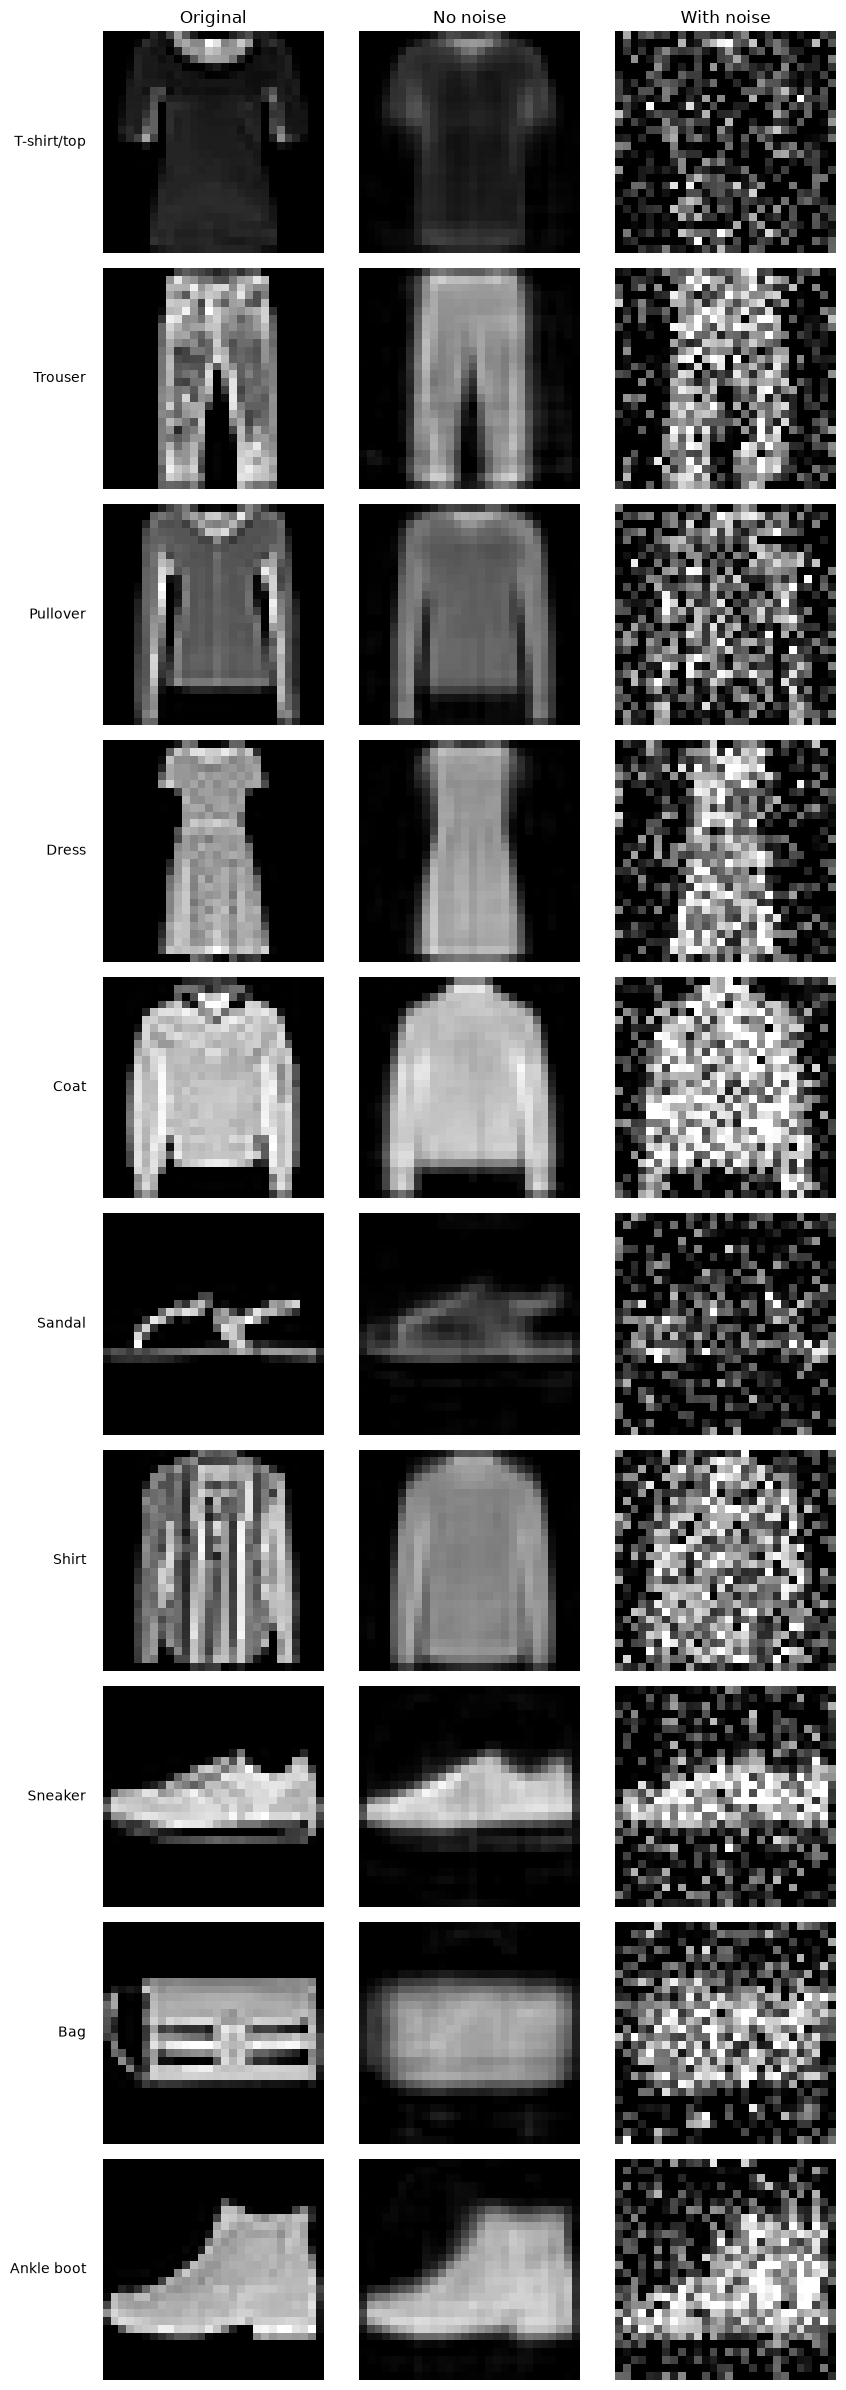

(<Figure size 900x2400 with 30 Axes>,
 array([[<Axes: title={'center': 'Original'}, ylabel='T-shirt/top'>,
         <Axes: title={'center': 'No noise'}>,
         <Axes: title={'center': 'With noise'}>],
        [<Axes: ylabel='Trouser'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Pullover'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Dress'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Coat'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Sandal'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Shirt'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Sneaker'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Bag'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Ankle boot'>, <Axes: >, <Axes: >]], dtype=object))

In [15]:
plot_reconstructions_by_label(best_model.vae_model, test_dataset)

In [16]:
class BernoulliDecoder(nn.Module):
    def __init__(self, decoder_net):
        super(BernoulliDecoder, self).__init__()
        self.decoder = decoder_net

    def decode(self, z):
        logits = self.decoder(z)
        probs = torch.sigmoid(logits)
        return probs

    def sample(self, z):
        probs = self.decode(z)
        return probs  # Return probabilities in [0,1]

    def log_prob(self, x, z):
        theta = self.decode(z)
        # BCE
        # Check x values are between 0 and 1
        if torch.any(x < 0) or torch.any(x > 1):
            raise ValueError('Input x must be in the range [0, 1] for Bernoulli log_prob computation.')
        log_prob = -F.binary_cross_entropy(theta, x, reduction='none').sum(dim=1)
        return log_prob

In [17]:
input_dim = train_dataset[0][0].numel()


num_hidden_layers = 2
num_hidden_layer_neurons = 64

latent_dim = 64



encoder =  Encoder(encoder_net=make_mlp(input_dim, 2 * latent_dim, num_hidden_layers, num_hidden_layer_neurons))
decoder = BernoulliDecoder(decoder_net=make_mlp(latent_dim, input_dim, num_hidden_layers, num_hidden_layer_neurons))


vae = VAE(encoder, decoder)

In [18]:
%%time

num_epochs = 20



lit_model = LitGenericVAEModel(vae_model=vae)

logger = CSVLogger(
    save_dir="lightning_logs",
    name="VAE_Bernoulli",
    version="fixed"
)


checkpoint = ModelCheckpoint(
    dirpath="./lightning_logs/VAE_Bernoulli/fixed/checkpoints",
    filename="vae-best-{epoch:02d}",
    monitor="loss.valid",
    mode="min",
    save_top_k=1,
)


early_stopping = EarlyStopping(
    monitor="loss.valid",
    mode="min",
    patience=5,
    min_delta=0.0,
)



trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=50,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger,
    callbacks=[checkpoint, early_stopping])

train_data_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightning_logs/VAE_Bernoulli/fixed exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/Topic4/lightning_logs/VAE_Bernoulli/fixed/checkpoints exists and is not empty.

  | Name      | Type | Params | Mode  | FLOPs
-------------------------------

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 19: 100%|██████████| 938/938 [00:05<00:00, 166.21it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 19: 100%|██████████| 938/938 [00:05<00:00, 165.91it/s, v_num=ixed]
CPU times: user 1min 12s, sys: 13.2 s, total: 1min 25s
Wall time: 1min 51s


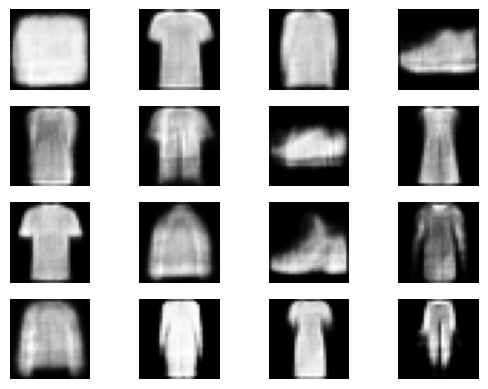

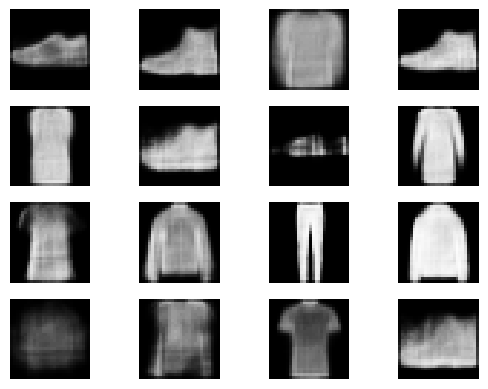

In [19]:
best_model = LitGenericVAEModel.load_from_checkpoint(
    checkpoint.best_model_path,
    vae_model=vae,
)

samples_generated_noise(best_model.vae_model)
samples_generated_no_noise(best_model.vae_model)


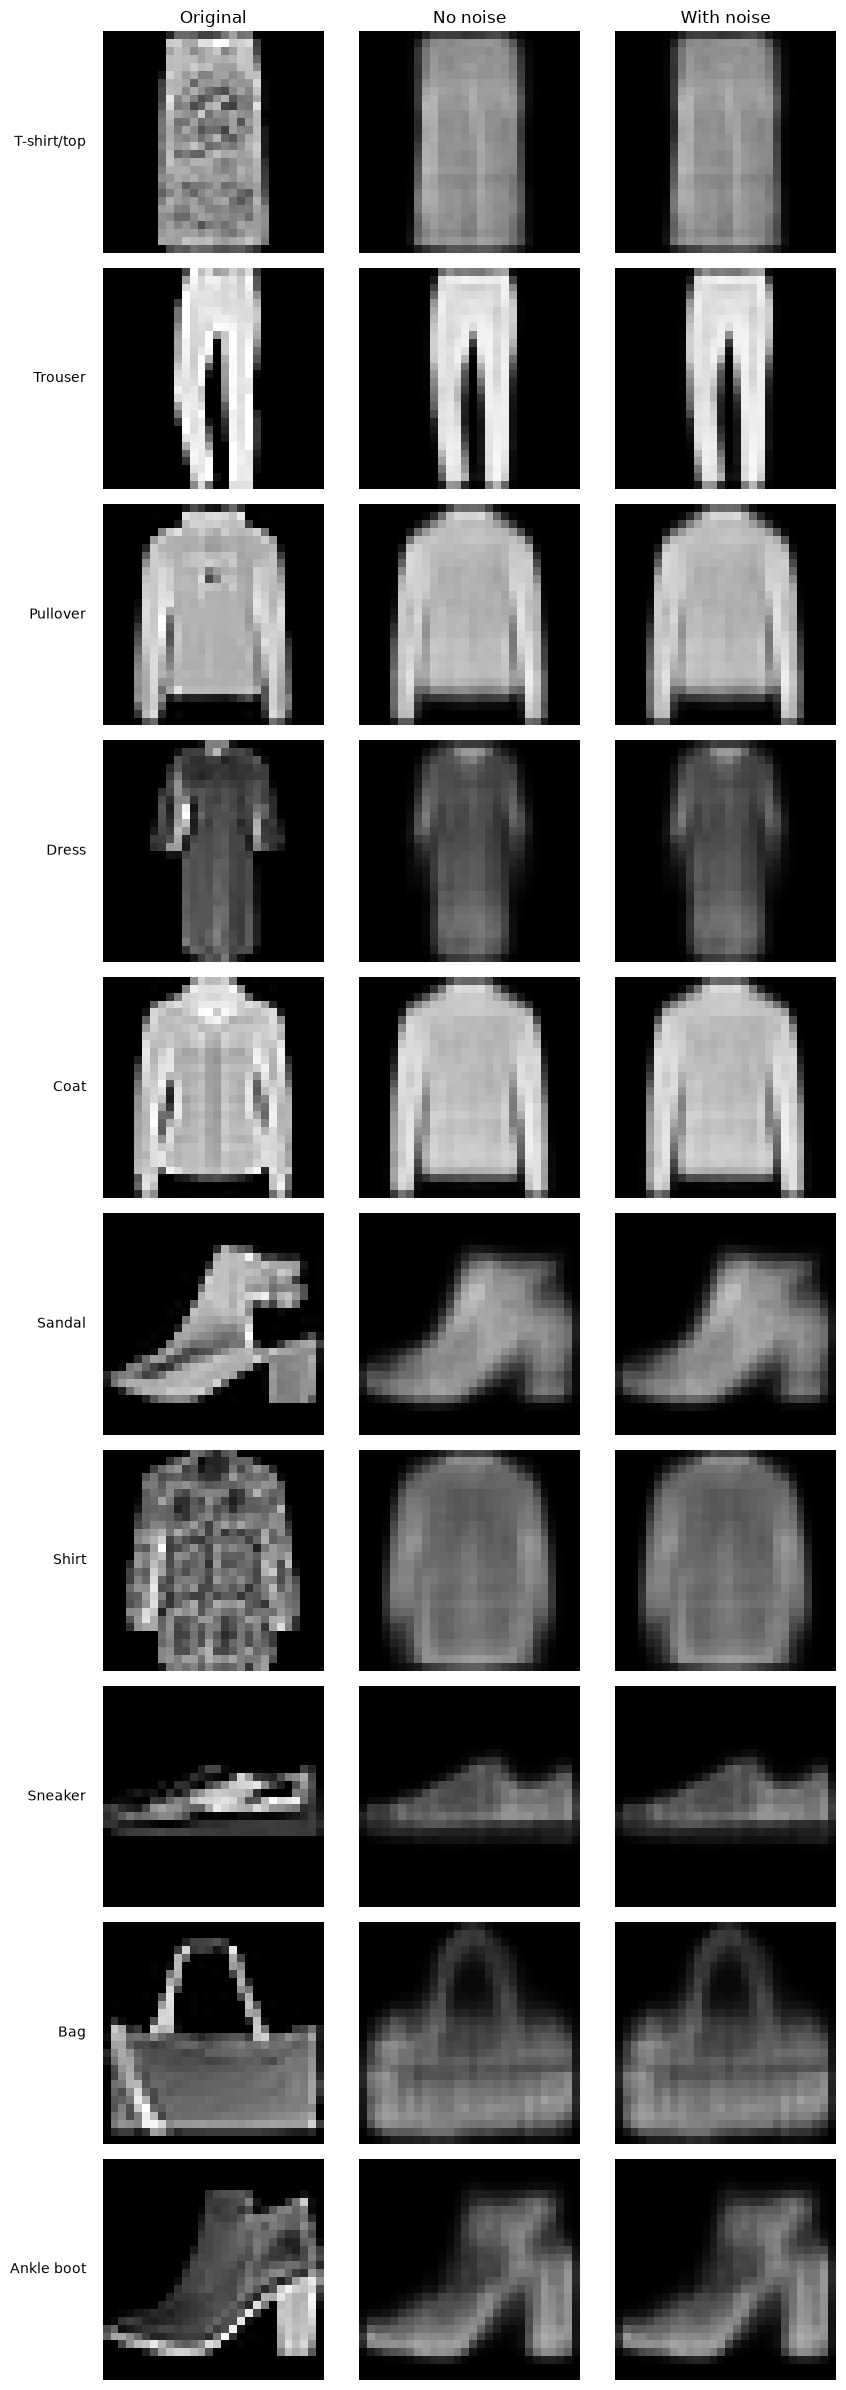

(<Figure size 900x2400 with 30 Axes>,
 array([[<Axes: title={'center': 'Original'}, ylabel='T-shirt/top'>,
         <Axes: title={'center': 'No noise'}>,
         <Axes: title={'center': 'With noise'}>],
        [<Axes: ylabel='Trouser'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Pullover'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Dress'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Coat'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Sandal'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Shirt'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Sneaker'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Bag'>, <Axes: >, <Axes: >],
        [<Axes: ylabel='Ankle boot'>, <Axes: >, <Axes: >]], dtype=object))

In [20]:
plot_reconstructions_by_label(best_model.vae_model, test_dataset)

## Exercise 2: Advanced VAE - GMM-VAE or VQ-VAE

Based on your results from Exercise 1, choose the best encoder likelihood and complete the following tasks:
1. Implement and train either a GMM-VAE or a VQ-VAE using the best likelihood from Exercise 1.
2. Visualize and analyze the latent space of your chosen model.
3. Compare the results with the standard VAE.

## Exercise 3: Comparison with Conditional Models

In this section, you will:
- Compare the latent spaces of your advanced VAE (GMM-VAE or VQ-VAE) with a conditional VAE.
- Discuss similarities and differences in the latent representations.




### Conditional Generative Models
There are three types of variables in a deep conditional generative model (CGM): input variables $\mathbf{y}$, output variables $\mathbf{x}$, and latent variables $\mathbf{z}$. The conditional generative process of the model is as follows: for a given observation $\mathbf{y}$, $\mathbf{z}$ is drawn from the prior distribution $p_\theta(\mathbf{z}|\mathbf{y})$, and the output $\mathbf{x}$ is generated from the distribution $p_\theta(\mathbf{x}|\mathbf{y}, \mathbf{z})$. The prior of the latent variables $\mathbf{z}$ is modulated by the input $\mathbf{y}$ in our formulation; however, the constraint can be easily relaxed to make the latent variables statistically independent of input variables, i.e., $p_\theta(\mathbf{z}|\mathbf{y}) = p_\theta(\mathbf{z})$.


In [21]:
from graphviz import Digraph
from IPython.display import display, Markdown


def is_google_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False


# Run this if we are in google colab
if is_google_colab():
    # First diagram: Generative model
    g1 = Digraph('Generative_Model')
    g1.attr(rankdir='LR')
    g1.node('Y')
    g1.node('X')
    g1.node('Z')
    g1.edge('Y', 'Z', label='p_θ(z|y)')
    g1.edge('Z', 'X')
    g1.edge('Y', 'X', label='p_θ(x|y,z)')

    # Second diagram: Recognition (inference) model
    g2 = Digraph('Recognition_Model')
    g2.attr(rankdir='LR')
    g2.node('Y')
    g2.node('X')
    g2.node('Z')
    g2.edge('Y', 'Z')
    g2.edge('X', 'Z', label='q_ϕ(z|y,x)')

    # Display with titles
    display(Markdown("### Conditional Generative Model"))
    display(g1)
    display(Markdown("### Recognition Model"))
    display(g2)


ModuleNotFoundError: No module named 'graphviz'

Deep CGMs are trained to maximize the conditional log-likelihood. Often the objective function is intractable, and we apply the stochastic variational inference framework to train the model. The variational lower bound of the model is written as follows:

\begin{equation}
\log p_\theta(\mathbf{x}|\mathbf{y}) \geq -\mathrm{KL}\left(q_\phi(\mathbf{z}|\mathbf{x}, \mathbf{y}) \| p_\theta(\mathbf{z}|\mathbf{y})\right) + \mathbb{E}_{q_\phi(\mathbf{z}|\mathbf{x}, \mathbf{y})}\left[\log p_\theta(\mathbf{x}|\mathbf{y}, \mathbf{z})\right]
\end{equation}

and the empirical lower bound is written as:

\begin{equation}
\widetilde{\mathcal{L}}_{\text{CVAE}}(\mathbf{x}, \mathbf{y}; \theta, \phi) = -\mathrm{KL}\left(q_\phi(\mathbf{z}|\mathbf{x}, \mathbf{y}) \| p_\theta(\mathbf{z}|\mathbf{y})\right) + \frac{1}{L} \sum_{l=1}^{L} \log p_\theta(\mathbf{x}|\mathbf{y}, \mathbf{z}^{(l)}),
\end{equation}

where $\mathbf{z}^{(l)} = g_\phi(\mathbf{x}, \mathbf{y}; \epsilon^{(l)})$, $\epsilon^{(l)} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $L$ is the number of samples. We call this model *conditional variational auto-encoder* (CVAE). The CVAE is composed of multiple MLPs, such as recognition network $q_\phi(\mathbf{z}|\mathbf{x}, \mathbf{y})$, (conditional) prior network $p_\theta(\mathbf{z}|\mathbf{y})$, and generation network $p_\theta(\mathbf{x}|\mathbf{y}, \mathbf{z})$.


### Implementing a Conditional VAE

#### **1. Implement a CVAE with Independent Prior**

- Use a **standard Gaussian prior**: $p(\mathbf{z}) = \mathcal{N}(0, I)$
- In this setting:
  - $\mathbf{y}$: class label (0–9)
  - $\mathbf{x}$: FMNIST image
- Feed the label $\mathbf{y}$ to the **decoder** $p_\theta(\mathbf{x} \mid \mathbf{y}, \mathbf{z})$, using either:
  - One-hot encoding
  - A learnable [embedding layer](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html)



#### **2. Modify the Prior to be Label-Dependent**

- Replace the independent prior with a **label-conditional prior**:

$$
p_\theta(\mathbf{z} \mid \mathbf{y})
$$

- Implement this using a small MLP that takes the class label as input (one-hot or embedding layer) and outputs $\mu(\mathbf{y})$, $\log\sigma^2(\mathbf{y})$
- Update the KL divergence accordingly:

$$
\mathrm{KL}\left(q_\phi(\mathbf{z} \mid \mathbf{x}, \mathbf{y}) \,\|\, p_\theta(\mathbf{z} \mid \mathbf{y})\right)
$$

In both cases:
- Plot the evolution of:
  - Total loss
  - KL divergence
  - Reconstruction loss
- After training:
  - Generate samples for each class label $\mathbf{y}$
  - Use the recognition network $q_\phi(\mathbf{z} \mid \mathbf{x}, \mathbf{y})$ to encode real test images
  - Visualize the resulting latent space using **t-SNE**, colored by class



## **Part 2: Missing Data Imputation with VAEs**

In this exercise, you'll work with the [Spambase dataset](https://archive.ics.uci.edu/dataset/94/spambase) from the UCI Machine Learning Repository. The goal is to use **Variational Autoencoders (VAEs)** to impute artificially introduced missing values in tabular data.

---

### **Step-by-Step Instructions**

1. **Download and Prepare the Dataset**
   - Load the Spambase dataset.
   - Normalize all features (ignore the `spam` label for now).
   - Split the dataset into **train** and **test** sets.

2. **Train a VAE**
   - Train a standard VAE using only the **clean (complete)** training set (i.e. no missing values).

3. **Simulate Missing Data in the Test Set**
   - Generate a **binary mask** for the test set where each entry has an 80% chance of being retained (True) and a 20% chance of being masked (False).
   - Replace all entries marked as missing (mask = False) with **zero**.

4. **Impute Missing Values**
   - Pass the **masked test set** through the VAE encoder.
   - Sample from the latent space and reconstruct the input using the decoder.
   - Use the decoder's output as the **imputed version** of the masked data.

5. **Evaluate Imputation Quality**
   - Compute the **Mean Squared Error (MSE)** and **R² score** over the **missing entries only** by comparing the imputed values against the original (unmasked) test set.

6. **Train a VAE with Random Masks (Imputation-Aware Training)**
   - Modify the training process:
     - At each iteration, apply a **random mask** to the training data (e.g. 20% of values masked).
     - Set the missing values to **0**.
     - Feed the masked data to the encoder.
     - When computing the loss (ELBO), evaluate **reconstruction over all entries (both observed and artificially masked)**.
     - KL divergence is computed as usual.

7. **Re-evaluate on the Test Set**
   - Using the **retrained VAE**, repeat Steps 3–5:
     - Apply a 20% missing mask to the test set.
     - Perform imputation using the retrained model.
     - Compute and report **MSE** and **R²** over the missing values.
